# Giorgos Moirotsos - University of Thessaly
# ECE352 Image Processing
# Assignment 1 

In [1]:
import numpy as np
import imageio.v2 as imageio
import math
import matplotlib.pyplot as plt
import cv2
from PIL import Image

- Read the images

Shape of Image 1: (512, 512)
Shape of Image 2: (256, 256)
Shape of Image 3: (661, 661)


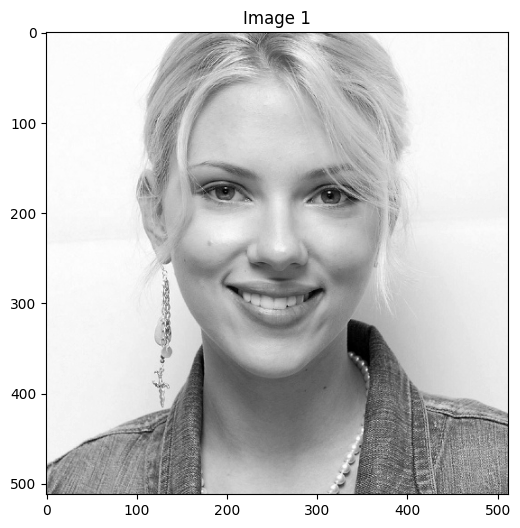

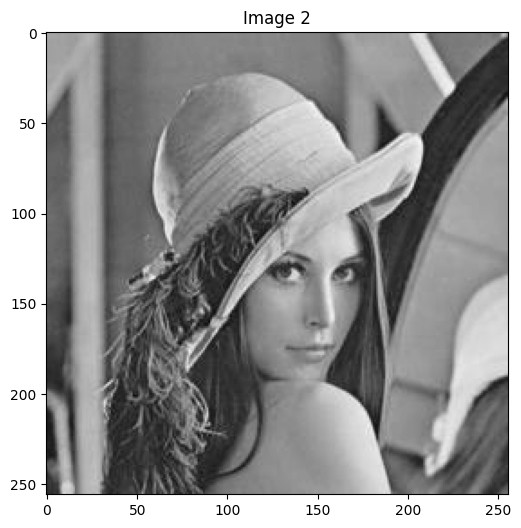

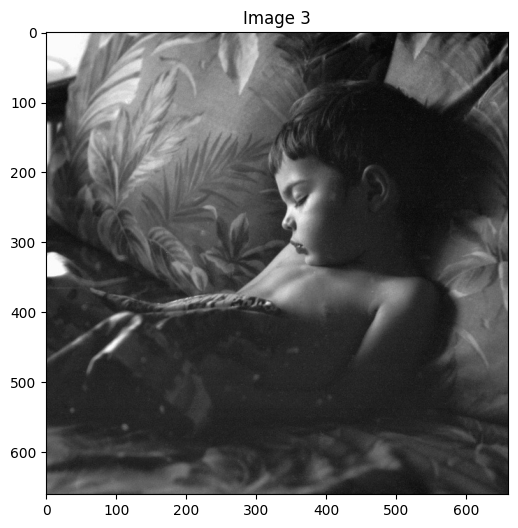

In [2]:
N=3     # 3 images
image = np.empty(N, dtype=object)

image[0] = imageio.imread('scarlett.jpg')
image[1] = imageio.imread('Lena.jpg')
image[2] = imageio.imread('nap.jpg')


for i in range(N):
    print(f"Shape of Image {i+1}: {image[i].shape}")
    plt.figure(figsize=(6,6))
    plt.title(f"Image {i+1}")
    plt.imshow(image[i], cmap="gray")

# Άσκηση 1.α

- **συνάρτηση για το αρνητικό μιας εικόνας**

In [3]:
def convert_into_negative(img, intensity):

    img = img / 255
    intensity = np.max(img)
    height, width = img.shape
    negative_img = np.zeros((height, width))

    for i in range(height):
        for j in range(width):
            negative_img[i][j] = intensity - img[i][j]
    
    return negative_img

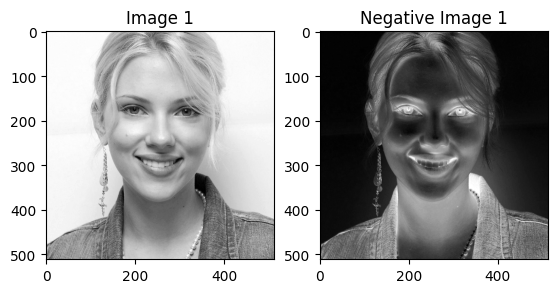

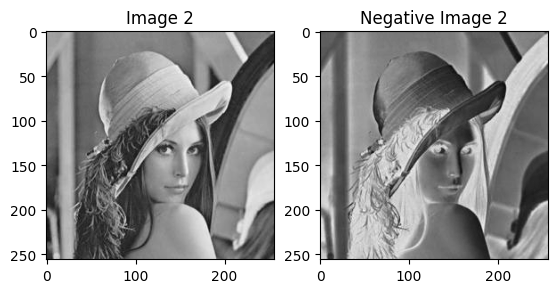

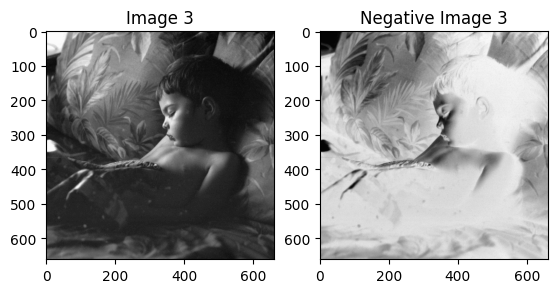

In [4]:
negative_image = np.empty(N, dtype=object)

for i in range(N):
    
    negative_image[i] = convert_into_negative(image[i], intensity=None)

    plt.figure(figsize=(10,10))

    plt.subplot(131)
    plt.title(f"Image {i+1}")
    plt.imshow(image[i], cmap="gray")

    plt.subplot(132)
    plt.title(f"Negative Image {i+1}")
    plt.imshow(negative_image[i], cmap="gray")

- οι τιμές των pixels δίνονται στο εύρος [0,1] (διαιρώντασ κάθε τιμή με το 255), για διευκόλυνση
- το αρνητικό μιας εικόνας δίνεται με την αφαίρεση κάθε pixel της συγκεκριμένης εικόνας από τη μέγιστη ένταση της εικόνας (συνήθως 255)
- συνήθως: 255 - img[i][j] (ή 1 - img[i][j] αν έχει γίνει κανονικοποίηση στο [0,1])
- τιμή pixel ίση με 0 ισοδυναμεί σε άσπρο
- τιμή pixel ίση με 255 (ή 1) ισοδυναμεί σε μαύρο
- ενδιάμεσες τιμές ισυδυναμούν σε ποιο γκρίζες τιμές 
- με το αρνητικό μιας εικόνας οι άσπρες περιοχές της αρχικής εικόνας μετατρέπονται σε μαύρες και το αντίστροφο

# Συμπεράσματα στις εικόνες
- στην πρώτη εικόνα παρατηρείται έντονο λευκό background. Με το αρνητικό της εικόνας το background μετατρέπεται σε μάυρο
- το background είναι σχετικά γκρίζο. Γι' αυτό τον λόγο, στο αρνητικό της εικόνας το background δεν αλλάζει ραγδαία και παραμένει σχετικά γκρίζο. Αυτό συμβαίνει καθώς η τιμή ενός γκρίζου pixel κυμαίνεται στο 125. Το αρνητικό αυτής της τιμής είναι 255-125=125, δηλαδή παραμένει ίδια. Συνεπώς στις γκρίζες περιοχές δεν έχουμε έντονη αλλαγή χρώματος

# Άσκηση 1.β

- **συνάρτηση για τον μετασχηματισμό Gamma**

In [5]:
def gamma_transform(img, gamma):

    height, width = img.shape
    gamma_img = np.zeros((height,width))

    for i in range(height):
        for j in range(width):
            gamma_img[i][j] = img[i][j]**gamma
    
    return gamma_img

- Η παρακάτω εικόνα αρχικά εμφανίζει τρεις διαστάσεις (μέγεθος πίνακα). Την μετατρέπουμε σε εικόνα δύο διαστάσεων.

(164, 220, 4)
(164, 220)


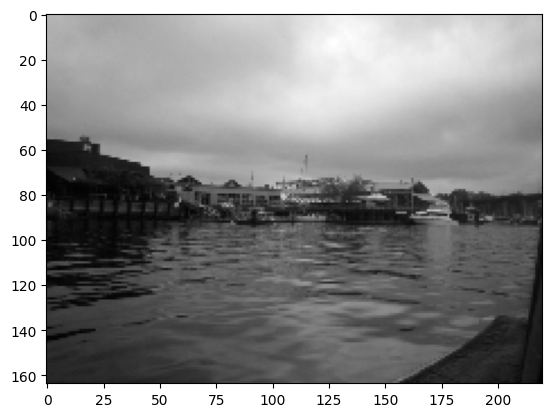

In [6]:
gamma_image = imageio.imread('gamma-corr.png')
print(gamma_image.shape)

#transform it into 2d array
gamma_image = 0.3*gamma_image[:,:,0] + 0.6*gamma_image[:,:,1] + 0.1*gamma_image[:,:,2]
print(gamma_image.shape)

plt.imshow(gamma_image, cmap="gray")

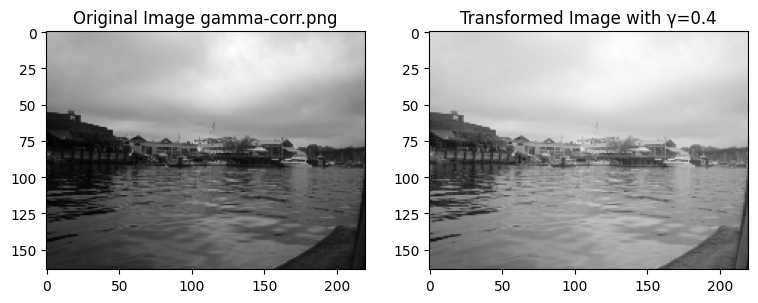

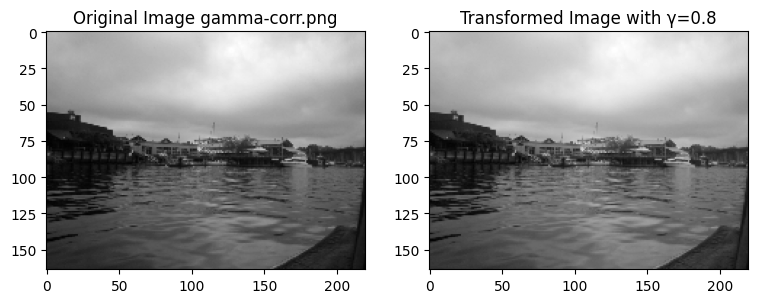

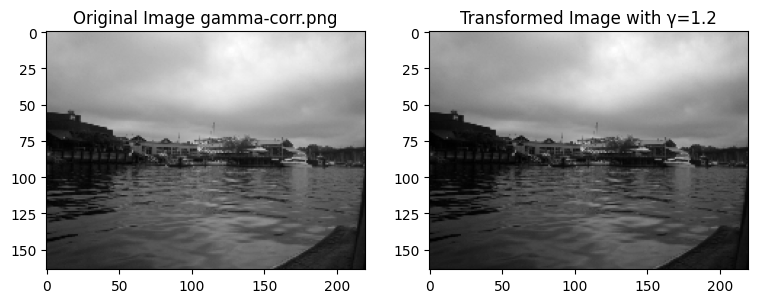

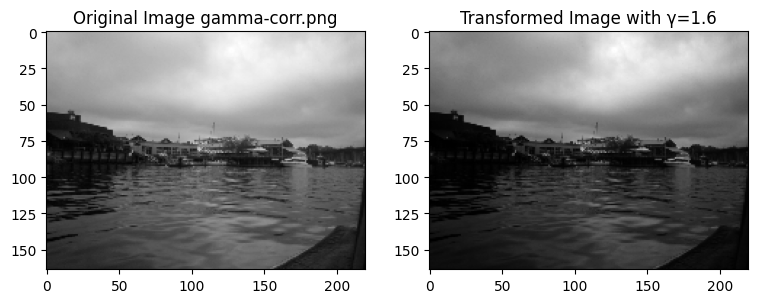

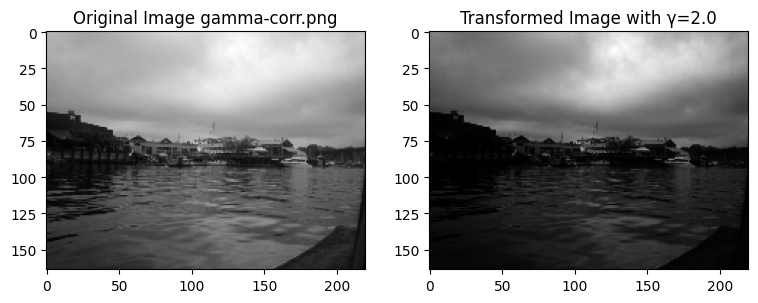

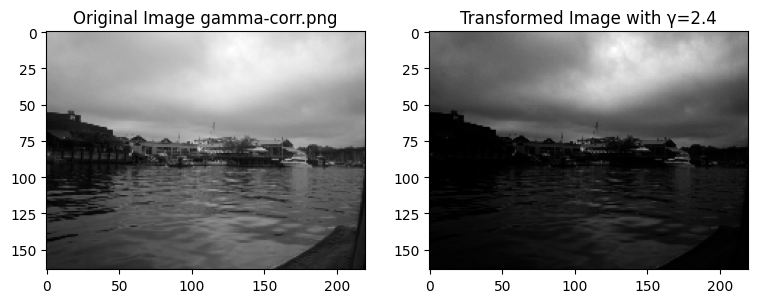

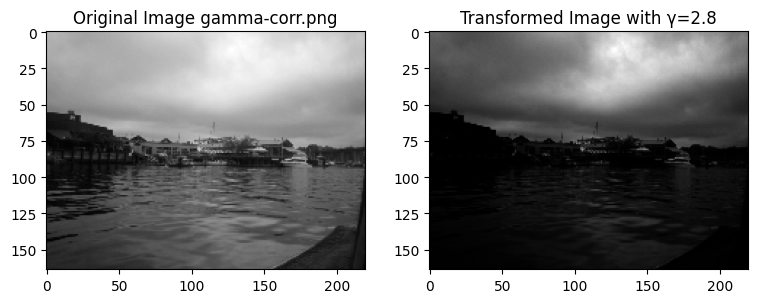

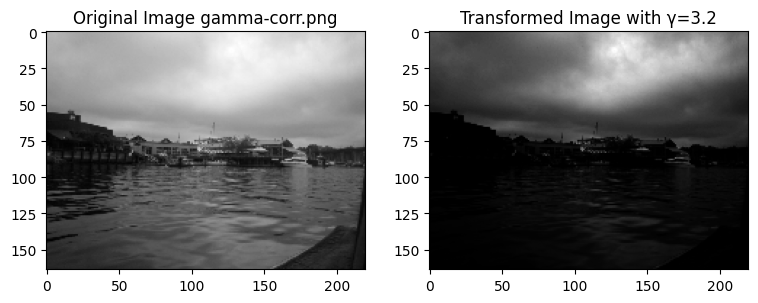

In [7]:
#gamma_image = imageio.imread('gamma-corr.png')

#normalize the pixel values in the range [0,1]
gamma_image = gamma_image / 255.0

#print(np.min(gamma_image))
#print(np.max(gamma_image))

gamma =0.4

for i in range(8):      #8 different gamma's starting from gamma=0.4

    new_gamma = gamma_transform(gamma_image, gamma)

    plt.figure(figsize=(14,14))

    plt.subplot(131)
    plt.imshow(gamma_image, cmap="gray")
    plt.title("Original Image gamma-corr.png")

    plt.subplot(132)
    plt.imshow(new_gamma, cmap="gray")
    plt.title(f"Transformed Image with γ={gamma:.1f}")

    gamma +=0.4

# Σχόλια
- Ο μετασχηματισμός Gamma υψύνει την τιμή κάθε pixel της αρχικής εικόνας στην δύναμη γ
- Ξεκινάμε με γ=0.4 και το αυξάνουμε κατά 0.4 έως γ=3.2 (σύνολο 8 διαφορετικών γ)
- Όσο πιο μεγάλο είναι το γ, τόσο πιο σκοτεινή γίνεται η εικόνα στο σύνολο της
- Προφανώς, τα pixels ίσα με 0 (πολύ λευκές περιοχές) και τα pixels ίσα με 255 (πολύ σκοτεινές περιοχές), δεν αλλάζουν κατά τον μετασχηματισμό Gamma, καθώς αν τα υψώσουμε σε μία δύναμη, το αποτέλεσμα παραμένει ίδιο.
- Οι γκρίζες περιοχές είναι αυτές που επηρεάζονται περισσότερο και γίνονται όλο και πιο σκούρες με την αύξηση του γ

# Άσκηση 2.α

- **συνάρτηση average_filter**

In [8]:
# function for convolution between image and kernel
from scipy.signal import convolve2d

def average_filter(img, size_filter):

    filter = np.zeros((size_filter,size_filter))
    filter[:size_filter] = 1/(size_filter)**2
    
    filtered_image = convolve2d(img, filter, mode='same', boundary='fill', fillvalue=0)

    return filtered_image



# Σχόλια
- Ένα average filter διαστάσεων NxN είναι ένα φίλτρο όπου κάθε κελί εχει τιμή (1/Ν)**2, δηλαδή το άθροισμα όλων των pixels ισοδυναμεί με 1
- Αποτελεί ένα από τα πιο απλά φίλτρα αφαίρεσης θορύβου
- Πραγματοποιείται συνέλιξη μεταξύ της αρχικής εικόνας και του average filter 
- Παράγεται μια πιο smooth εικόνα
- Όσο μεγαλύτερο είναι το μέγεθος του φίλτρου, τόσο πιο θολή είναι η εικόνα και τόσες περισσότερες λεπτομέρειες χάνονται απο την εικόνα

# Άσκηση 2.β

In [65]:
x = np.array([[6,2,3],[1,5,6]])
print(x)

flat = x.flatten()
sorted_values = np.sort(flat)
n = len(sorted_values)
m1 = (n//2) - 1 
m2 = n//2
median1 = sorted_values[m1]
median2 = sorted_values[m2]
median_value = max(median1, median2)

print(flat)
print(sorted_values)
print(median1)
print(median2)
print(median_value)

[[6 2 3]
 [1 5 6]]
[6 2 3 1 5 6]
[1 2 3 5 6 6]
3
5
5


- **συνάρτηση median_filter**

In [73]:
def median_filter(img, size_filter):
    
    pad_h = size_filter // 2
    pad_w = size_filter// 2
    padded_image = np.pad(img, pad_width=((pad_h, pad_h), (pad_w, pad_w)), mode='edge')


    height, width = img.shape

    new_image = np.empty((height,width), dtype=object)

    for i in range(height):
        for j in range(width):

            if size_filter%2==1:
                k = size_filter//2
                window = padded_image[i : i + 2*k + 1, j : j + 2*k + 1]
           
                flat = window.flatten()
                sorted_values = np.sort(flat)
                median_value = np.median(sorted_values)

                new_image[i][j] = median_value
                
            elif size_filter%2==0:
                k = size_filter//2
                window = padded_image[i : i + 2*k + 1, j : j + 2*k + 1]
                flat = window.flatten()
                sorted_values = np.sort(flat)
                n = len(sorted_values)
                m1 = (n//2) - 1 
                m2 = n//2
                median1 = sorted_values[m1]
                median2 = sorted_values[m2]
                median_value = max(median1, median2)

                new_image[i][j] = median_value


    return new_image

# Τι είναι ένα median filter
- Το median filter είναι ένα μη γραμμικό φίλτρο
- αφαιρεί θόρυβο από την εικόνα (κυρίως salt and pepper θόρυβο)
- διατηρεί καλύτερα τις ακμές από άλλα φίλτρα (πχ average filter)

# Πως δουλεύει ένα median filter
- Παίρνουμε ένα παράθυρο (συνήθως 3χ3, 5x5, 7x7 κτλ) γύρω από κάθε γειτονιά pixels
- Ταξινομούμε αυτά τα pixels κατά αύξουσα σειρά (μικρότερο προς μεγαλύτερο)
- Αντικαθιστούμε το κεντρικό pixel του παραθύρου στην εικόνα μας την μεσαία τιμή από τις ταξινομημένες
- Προκειμένου να μην χάσουμε πληροφορία από τα ακριανά pixels, προηγείται στην αρχική μασ εικόνα padding. Προσθέτουμε, δηλαδή, τεχνητά pixels γύρω από την εικόνα μας ώστε να εφαρμοστεί το φίλτρο παντού.

# Περίπτωση άρτιου μεγέθους σε ένα median φίλτρο
- Έαν το μέγεθος του φίλτρου είναι άρτιο (πχ 2x2, 6x6, 10x10), τότε κατά την ταξινόμιση των τιμών σε αύξουσα σειρά δεν προκύπτει μία μοναδική μεσαία τιμή.
- Αυτό που κάνουμε είναι να επιλέξουμε τις δύο μεσαίες τιμές του ταξινομημένου πίνακα, και από αυτές τις δύο τιμές να διαλέγουμε την μεγαλύτερη. Είναι επιλογή μας αν η τελική τιμή που θα επιλέξουμε από τις δύο μεσαίες θα είναι η μεγαλύτερη ή η μικρότερη.


# Άσκηση 2.γ

# Βήματα
1. Χρησιμοποιούμε το image[0] (scarlett.jpg)
2. κάνουμε normalize τις τιμές των pixels στο εύρος [0,1] (αντί για [0,255])
3. Βρίσκω την τυπική απόκλιση, η οποία είναι ίση με το 5% της μέσης τιμής της εικόνας
4. Εφαρμόζουμε τη συνάρτηση ranom_noise στο image[0] (την ονομάζουμε noisy_img) και την εκτυπώνουμε για να την συγκρίνουμε με την αρχική εικόνα
5. Εφαρμόζουμε το average filter διαστάσεων 3x3, 7x7, 11x11 στη noiy_img 
6. Εκτυπώνουμε και συγκρίνουμε τα αποτελέσματα

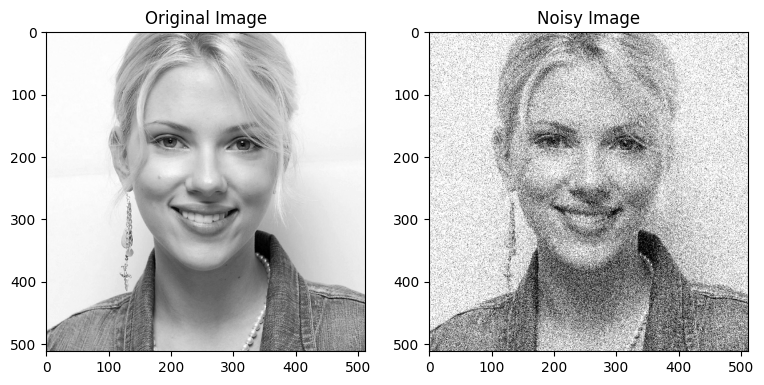

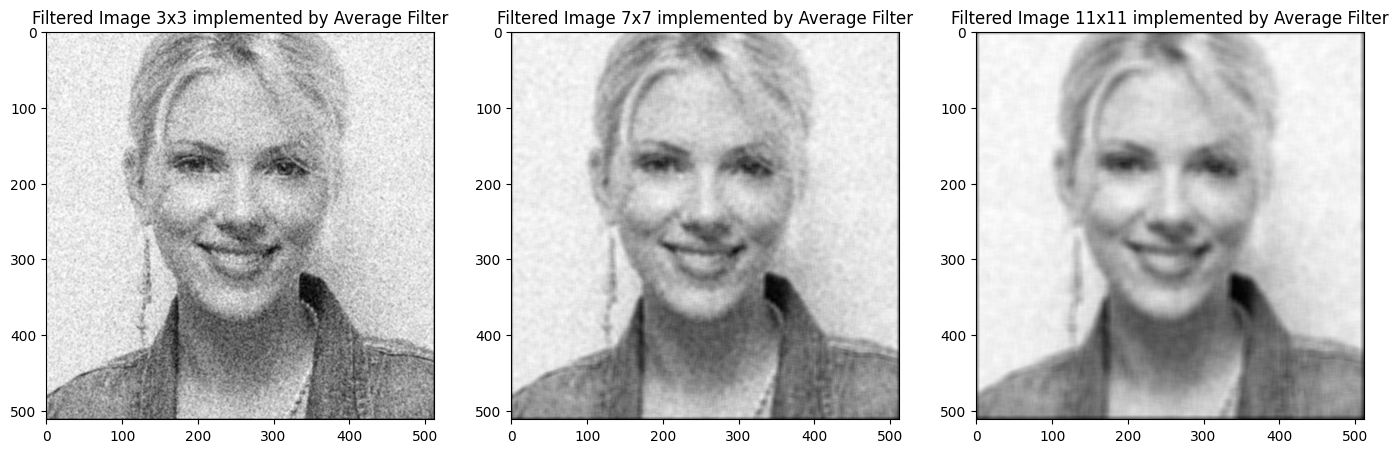

In [74]:
from skimage.util import random_noise

# image[0] --> scarlett.jpg
image[0] = imageio.imread('scarlett.jpg')

# find var
height, width = image[0].shape
image[0] = image[0] / 255       #normalize pixel values in [0,1]
total_sum = np.sum(image[0])
var1 = 0.05 * (total_sum / (height*width))      # 5% of average pixel intensity

#use random_noise to add noise 
noisy_img = random_noise(image[0], mode='gaussian', mean=0, var=var1)

# print noisy image and original image
plt.figure(figsize=(14,14))
plt.subplot(131)
plt.imshow(image[0], cmap="gray")
plt.title("Original Image")

plt.subplot(132)
plt.imshow(noisy_img, cmap="gray")
plt.title("Noisy Image")

dim=3       # 3x3, 7x7, 11x11
filtered_image = np.empty(dim, dtype=object)

size_filter = 3     #initialize filter's size 3x3
plt.figure(figsize=(17,17))

for i in range(dim):
    
    filtered_image[i] = average_filter(noisy_img, size_filter)      #implement avearge_filter into the noisy image

    plt.subplot(131+i)
    plt.imshow(filtered_image[i], cmap="gray")
    plt.title(f"Filtered Image {size_filter}x{size_filter} implemented by Average Filter")

    size_filter +=4     #3x3, 7x7, 11x11 (step)

# Άσκηση 2.δ

# Βήματα 
- πραγματοποιείται η ίδια διαδικασία με παραπάνω
- Αυτή τη φορά, εφαρμόζουμε το median filter διαστάσεων 3x3, 7x7, 11x11 στη noisy_img

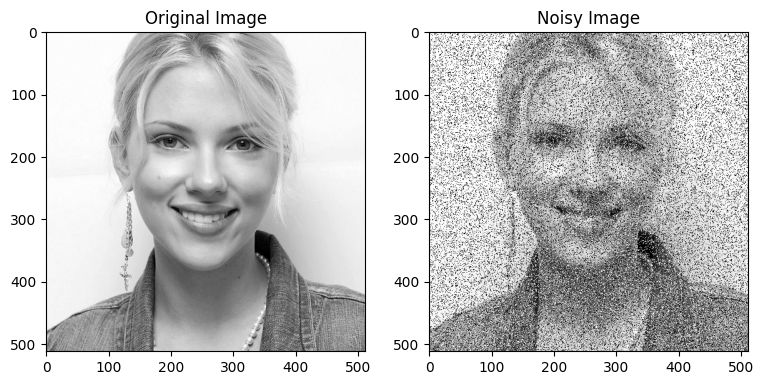

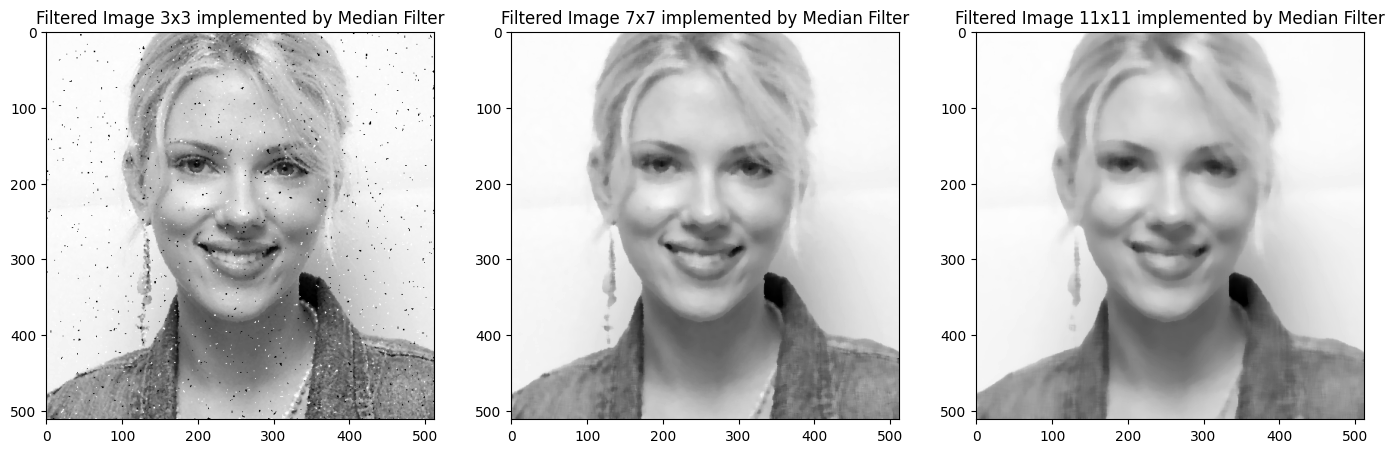

In [75]:
# image[0] --> scarlett.jpg
image[0] = imageio.imread('scarlett.jpg')

#use random_noise to add noise 
image[0] = image[0] / 255.0
noisy_img = random_noise(image[0], mode='s&p', amount=0.3)

# print noisy image and original image
plt.figure(figsize=(14,14))
plt.subplot(131)
plt.imshow(image[0], cmap="gray")
plt.title("Original Image")

plt.subplot(132)
plt.imshow(noisy_img, cmap="gray")
plt.title("Noisy Image")

dim=3       # 3x3, 7x7, 11x11
filtered_image = np.empty(dim, dtype=object)

filter_size = 3     #initialize filter's size 3x3
plt.figure(figsize=(17,17))

for i in range(dim):
    
    filtered_image[i] = median_filter(noisy_img, filter_size)      #implement avearge_filter into the noisy image

    plt.subplot(131+i)
    plt.imshow(np.array(filtered_image[i], dtype=np.float64), cmap="gray")
    plt.title(f"Filtered Image {filter_size}x{filter_size} implemented by Median Filter")

    filter_size +=4     #3x3, 7x7, 11x11 (step)

# Συμπεράσματα μεταξύ average filter και median filter
- Γίνεται εύκολα αντιληπτό πως το median filter έχει αφαιρέσει σε πολύ μεγάλο βαθμό τον salt and pepper θόρυβο, σε αντίθεση με το average filter όπου ο θόρυβος παραμένει.
- Στο median filter από το 7x7 και μετά ο θόρυβος έχει εξαφανιστεί εντελώς. Η εικόνα θολώνει όσο αυξάνεται το μέγεθος του φίλτρου.
- Στο average filter ο θόρυβος salt and pepper παραμένει έντονος ακόμα και όταν αυξάνεται το μέγεθος του φίλτρου. Η εικόνα θολώνει όσο αυξάνεται το μέγεθος του φίλτρου.
- Ακόμα και όταν μεγαλώνει το μέγεθος του median φίλτρου, οι ακμές είναι πολύ πιο διακριτές σε σχέση με το average φίλτρο όπου οι ακμές εξαφανίζονται τελείως.

# Άσκηση 3.α

- **συνάρτηση image_laplacian (εφαρμόζει τον laplacial τελεστή)**

In [13]:
def image_laplacian(img):
    
    kernel = np.array([[0,1,0],
                       [1,-4,1],
                       [0,1,0]])
    new_image = convolve2d(img, kernel, mode='same', boundary='fill', fillvalue=0)

    return new_image

# Σχόλια
- To laplacian filter είναι ένα φίλτρο ανίχνευσης ακμών πάνω στην εικόνα μας
- Ενισχύει περιοχές όπου η φωτεινότητα αλλάζει γρήγορα (συνήθως ακμή)
- Κάνει χρήση της δεύτερης παγαγώγου    
- Πρακτικά, εφαρμόζουμε συνέλιξη μεταξύ της εικόνας και ενός kernel ([0,1,0],[1,-4,1],[0,1,0])

# Άσκηση 3.β

Text(0.5, 1.0, 'Sharpened Image')

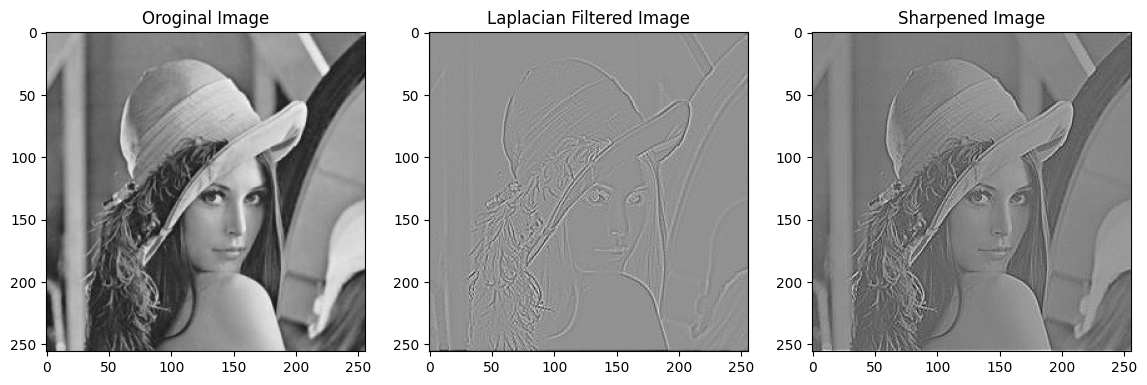

In [14]:
filtered_lena = image_laplacian(image[1])
sharpened_image = image[1] - filtered_lena

plt.figure(figsize=(14,14))

plt.subplot(131)
plt.imshow(image[1], cmap="gray")
plt.title("Oroginal Image")

plt.subplot(132)
plt.imshow(filtered_lena, cmap="gray")
plt.title("Laplacian Filtered Image")

plt.subplot(133)
plt.imshow(sharpened_image, cmap="gray")
plt.title("Sharpened Image")

# Συμπέρασμα
- Στη Lapcacian Image, παρατηρούμε πιο έντονες γραμμές (ακμές) σε περιοχές όπου η φωτεινότητα της αρχικής εικόνας αλλάζει έντονα
- Στη Sharpened Image (διαφορά αρχικής εικόνας από laplacian εικόνα) είναι πολύ πιο εύκολο και ορατό να αναγνωρίσουμε ακμές και λεπτομέρειες, σε σχέση με την αρχική εικόνα

# Άσκηση 3.γ

- **αλγόριθμος όξυνσης unsharp masking**

In [76]:
def unsharp_masking(img, blured_image, k):

    mask = img - blured_image
    unsharpened_image = img + k*mask

    return unsharpened_image

# Τι είναι το unshapr masking
- Το unsharp masking είναι μια τεχνική βελτίωσης εικόνας που χρησιμοποιείται για να ενισχύσει την οξύτητα (sharpness) και να κάνει τα περιγράμματα και τις λεπτομέρειες μιας εικόνας πιο ευδιάκριτα.
- Δίνει καθαρότερα περιγράμματα
- Αναδεικνύει μικρές λεπτομέρειες πάνω σε μία εικόνα
- Χρησιμοποιείται πολύ σε φωτογραφία, σάρωση εγγράφων, ακόμα και σε επεξεργασία video

# Βήματα αλγορίθμου unsharp_masking
- Εφάρμοσε ένα φίλτρο στην αρχική εικόνα, ώστε να γίνει πιο blurred
- αφαίρεσε την blurred εικόνα από την αρχική εικόνα. Το αποτέλεσμα ονομάζεται mask
- πρόσθεσε την αρχική εικόνα στην mask. H mask είναι πολλαπλασιασμένη με τον συντελεστή ενίσχυσης k. Το τελικό αποτέλεσμα ονομάζεται unsharpened_image

- **Εφάρμοσε για k=1, κάνοντας χρήση το φίλτρο της μέσης τιμής (average filter)**

Text(0.5, 1.0, 'Unsharped Image, k=1')

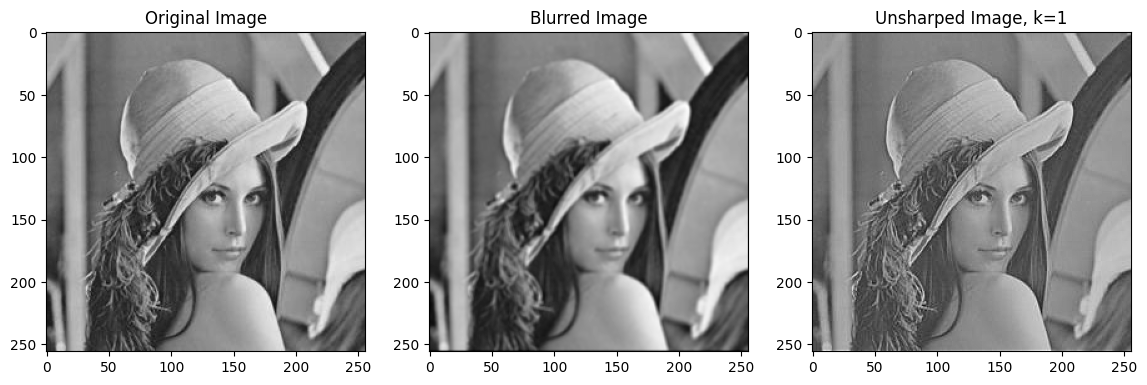

In [77]:
image[1] = imageio.imread('Lena.jpg')

#blur the image
filter_size=3
blurred_lena= average_filter(image[1], filter_size)

#unsharpened image
k=1
usharpened_lena = unsharp_masking(image[1], blurred_lena, k)

#plot original, blurred, unsharpened image
plt.figure(figsize=(14,14))

plt.subplot(131)
plt.imshow(image[1], cmap="gray")
plt.title('Original Image')

plt.subplot(132)
plt.imshow(blurred_lena, cmap="gray")
plt.title('Blurred Image')

plt.subplot(133)
plt.imshow(usharpened_lena, cmap="gray")
plt.title('Unsharped Image, k=1')

# Άσκηση 3.δ

- **κ>1 (μεταβαλλόμενο)**

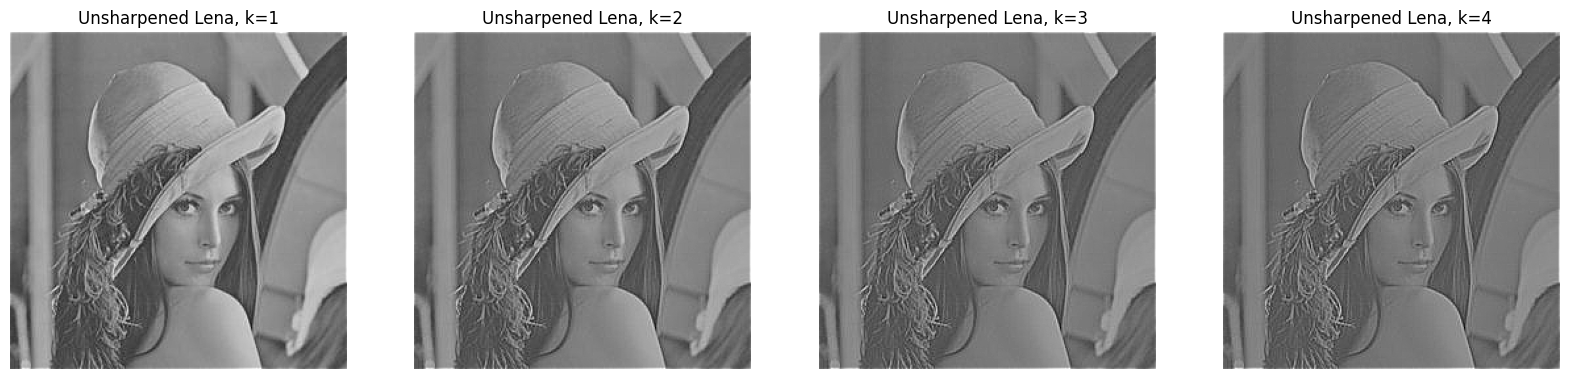

In [78]:
# download the image
image[1] = imageio.imread('Lena.jpg')

#blur the image
filter_size = 3
filtered_lena= average_filter(image[1], filter_size)

repeat = 4    # number of different k's
unsharpened_lena = np.empty(repeat, dtype=object)

k=1

for i in range(repeat):

    # apply the unsharp masking
    unsharpened_lena[i] = unsharp_masking(image[1], filtered_lena, k)
    k += 1
   

# plot the unsharpened images
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for i in range(repeat):
    axes[i].imshow(unsharpened_lena[i], cmap="gray")
    axes[i].axis('off')
    axes[i].set_title(f"Unsharpened Lena, k={i+1}")

    

# Σημασία του k
- Το k είναι ο συντελεστής ενίσχυσης τησ μάσκας
- Όσο μεγαλύτερο είναι το k, τόσο πιο έντονη είναι η όξυνση. Έντονη όξυνση σημαίνει πως μικρές λεπτομέρειες σε μία εικόνα (πχ φτερά καπέλου στην εικόνα μας) γίνονται όλο και πιο ορατές (διακριτές). 

# Συμπέρασμα για τα διαφορετικά k

- Παραπάνω εμφανίζονται 4 unsharpened εικόνες, με το k να αυξάνεται κατά μία μονάδα από τα αριστερά προς τα δεξιά
- Παρατηρούμε ότι όσο αυξάνεται το k, τόσο πιο ορατές γίνονται οι μικρές λεπτομέρειες της εικόνας, όπως τρίχες μαλλιών, φτερά καπέλου, λεπτομέρειες καπέλου κτλ.
- Όσο αυξάνεται το k (ειδικά για κ=4), η εικόνα φαίνεται όλο και πιο "επεξεργασμένη" σε σχέση με την αρχική, με αποτέλεσμα να χάνει την φυσικότητά της
- Έαν ο στόχος μας είναι να διακρίνουμε λεπτομέρειες που, ενδεχομένως, να μην εμφανίζονται στην αρχική εικόνα, τότε ένα μεγάλο k (k=3 ή k=4) είναι η ιδανική επιλογή
- Έαν θένω να κρατήσω την φυσικότητα της αρχικής εικόνας, χρειάζομαι σχετικά μικρό k
- Το k=2 δίνει έναν συνδυασμό ορατών λεπτομερειών (σε σχέση με αρχική εικόνα) και φυσικότητας (σε σχέση με μεγαλύτερα k όπου το αποτέλεσμα φαίνεται πιο επεξεργασμένο)  